# Mini Assessment

# Questions and Coding Exercises

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Age": [22, 25, 28, 30, 35, 40, 45, 50, 29, 32, 27, 70],
    "Experience": [1, 3, 5, 7, 10, 15, 18, 22, 6, 8, 4, 35],
    "Orders": [1, 2, 3, 4, 5, 6, 7, 8, 3, 4, 2, 12],
    "Salary": [25000, 30000, 35000, 40000, 45000, 55000, 65000, 70000, 38000, 42000, 32000, 250000],
    "Department": ["IT", "HR", "IT", "Sales", "IT", "HR", "Sales", "IT", "Sales", "IT", "HR", "Sales"],
    "Purchased": ["No", "No", "Yes", "No", "Yes", "Yes", "Yes", "Yes", "No", "Yes", "No", "Yes"]
})
print(df.head())

   Age  Experience  Orders  Salary Department Purchased
0   22           1       1   25000         IT        No
1   25           3       2   30000         HR        No
2   28           5       3   35000         IT       Yes
3   30           7       4   40000      Sales        No
4   35          10       5   45000         IT       Yes


# What is EDA?
Answer: Exploratory Data Analysis means inspecting, summarizing, and visualizing data to understand its structure, quality, and patterns before modeling.

In [2]:
print("Sample dataset:")
print(df.head())

Sample dataset:
   Age  Experience  Orders  Salary Department Purchased
0   22           1       1   25000         IT        No
1   25           3       2   30000         HR        No
2   28           5       3   35000         IT       Yes
3   30           7       4   40000      Sales        No
4   35          10       5   45000         IT       Yes


# Question
Why is EDA performed before Machine Learning?

In [3]:
print("Missing values before ML:")
print(df.isna().sum())
print("\nNumerical summary:")
print(df[["Age", "Salary"]].describe())

Missing values before ML:
Age           0
Experience    0
Orders        0
Salary        0
Department    0
Purchased     0
dtype: int64

Numerical summary:
             Age         Salary
count  12.000000      12.000000
mean   36.083333   60583.333333
std    13.527469   61209.711549
min    22.000000   25000.000000
25%    27.750000   34250.000000
50%    31.000000   41000.000000
75%    41.250000   57500.000000
max    70.000000  250000.000000


# Question
What is the difference between univariate, bivariate, and multivariate analysis?

In [4]:
print("Univariate - average age:", df["Age"].mean())
print("Bivariate - age and salary correlation:", round(df["Age"].corr(df["Salary"]), 2))
print("Multivariate - correlation matrix:")
print(df[["Age", "Salary", "Orders"]].corr().round(2))

Univariate - average age: 36.083333333333336
Bivariate - age and salary correlation: 0.91
Multivariate - correlation matrix:
         Age  Salary  Orders
Age     1.00    0.91    0.99
Salary  0.91    1.00    0.87
Orders  0.99    0.87    1.00


# Question
How do you identify missing values in a dataset?

In [5]:
print("Missing values by column:")
print(df.isnull().sum())

Missing values by column:
Age           0
Experience    0
Orders        0
Salary        0
Department    0
Purchased     0
dtype: int64


# Question
How do you identify duplicate records?

In [6]:
print("Duplicate row count:", df.duplicated().sum())
print("Duplicate rows:")
print(df[df.duplicated()])

Duplicate row count: 0
Duplicate rows:
Empty DataFrame
Columns: [Age, Experience, Orders, Salary, Department, Purchased]
Index: []


# Question
What is an outlier?

In [7]:
print("Salary values:", df["Salary"].tolist())
print("Highest salary:", df["Salary"].max())

Salary values: [25000, 30000, 35000, 40000, 45000, 55000, 65000, 70000, 38000, 42000, 32000, 250000]
Highest salary: 250000


# Question
Explain the IQR method for detecting outliers.

In [8]:
q1 = df["Salary"].quantile(0.25)
q3 = df["Salary"].quantile(0.75)
iqr = q3 - q1
print("IQR:", iqr)
print("Outlier salaries:", df.loc[(df["Salary"] < q1 - 1.5 * iqr) | (df["Salary"] > q3 + 1.5 * iqr), "Salary"].tolist())

IQR: 23250.0
Outlier salaries: [250000]


# Question
What is skewness?

In [9]:
print("Salary skewness:", round(df["Salary"].skew(), 2))

Salary skewness: 3.16


# Question
What is correlation?

In [10]:
print("Age and Salary correlation:", round(df["Age"].corr(df["Salary"]), 2))

Age and Salary correlation: 0.91


# Question
What is the difference between correlation and causation?

In [11]:
print("Ice cream sales and temperature may correlate without temperature directly causing every sale.")
temperature = pd.Series([20, 25, 30, 35, 40])
ice_cream_sales = pd.Series([10, 18, 24, 32, 40])
print("Illustrative correlation:", round(temperature.corr(ice_cream_sales), 2))

Ice cream sales and temperature may correlate without temperature directly causing every sale.
Illustrative correlation: 1.0


# Question
What is multicollinearity?

In [12]:
print("Feature correlations (check for multicollinearity):")
print(df[["Age", "Experience", "Salary"]].corr().round(2))

Feature correlations (check for multicollinearity):
             Age  Experience  Salary
Age         1.00        1.00    0.91
Experience  1.00        1.00    0.89
Salary      0.91        0.89    1.00


# Question
How do you identify class imbalance?

In [13]:
print("Target class counts:")
print(df["Purchased"].value_counts())
print("Target percentages:")
print((df["Purchased"].value_counts(normalize=True) * 100).round(1))

Target class counts:
Purchased
Yes    7
No     5
Name: count, dtype: int64
Target percentages:
Purchased
Yes    58.3
No     41.7
Name: proportion, dtype: float64


# Question
Why should outliers not always be removed?

In [14]:
import pandas as pd

df = pd.DataFrame({"Purchase": [1000, 1200, 1500, 1800, 100000]})

print(df)
print("High purchase may be genuine, so don't remove it automatically.")

   Purchase
0      1000
1      1200
2      1500
3      1800
4    100000
High purchase may be genuine, so don't remove it automatically.


# Coding Exercises
The following examples use a small sample dataset created in Python. Run the setup cell first.

# Correlation Heatmap
Task: Create a correlation heatmap for numerical features.

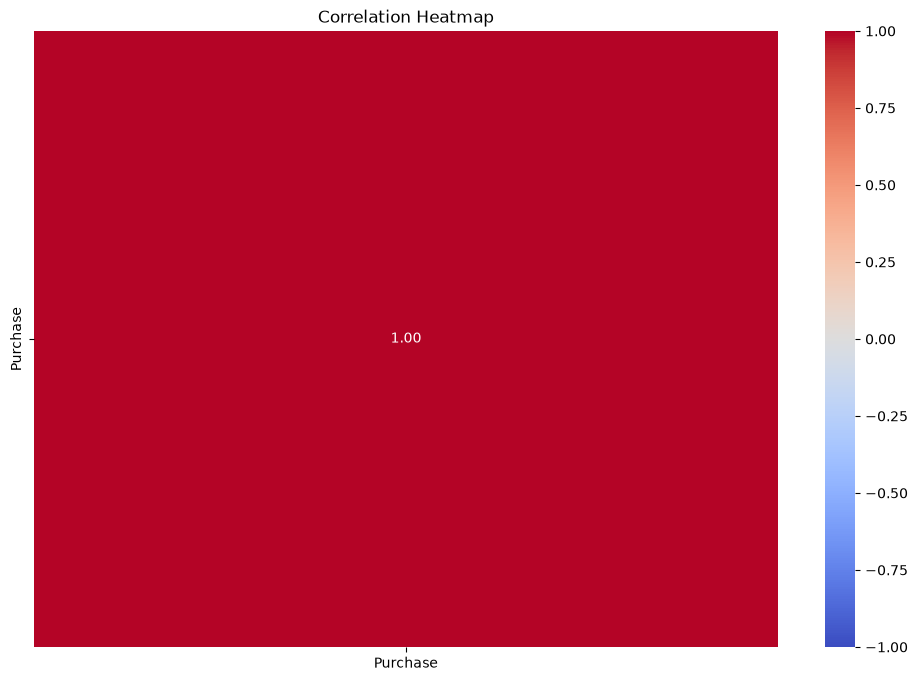

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numerical_df = df.select_dtypes(include="number")

# Calculate correlation
correlation = numerical_df.corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

# Detect Outliers Using IQR
Task: Detect outliers in the Salary column using the IQR method.

In [19]:
import pandas as pd
import numpy as np

# Select numerical columns
numerical_df = df.select_dtypes(include="number")

# Calculate Q1, Q3, and IQR for each numerical column
for column in numerical_df.columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Identify outliers
    outliers = df[(df[column] < lower) | (df[column] > upper)]

    print(f"\nColumn: {column}")
    print("Lower bound:", lower)
    print("Upper bound:", upper)
    print("Number of outliers:", len(outliers))
    print("Outliers:\n", outliers[[column]])


Column: Purchase
Lower bound: 300.0
Upper bound: 2700.0
Number of outliers: 1
Outliers:
    Purchase
4    100000


# Numerical Feature Distribution
Task: Analyze the distribution of Salary using a histogram and summary statistics.

Available columns: ['Purchase']
Numerical columns: ['Purchase']

Analyzing: Purchase
Mean: 21100.0
Median: 1500.0
Skewness: 2.24


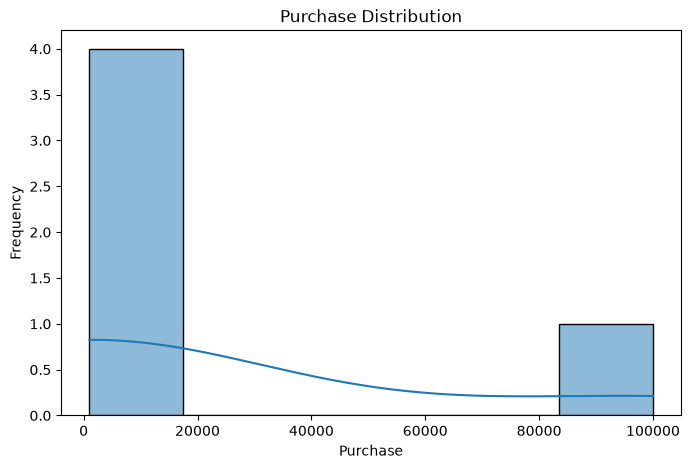

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Check available columns
print("Available columns:", df.columns.tolist())

# Select numerical columns
numerical_columns = df.select_dtypes(include="number").columns

print("Numerical columns:", numerical_columns.tolist())

# Analyze the first available numerical column
if len(numerical_columns) > 0:
    column = numerical_columns[0]

    print(f"\nAnalyzing: {column}")
    print("Mean:", df[column].mean())
    print("Median:", df[column].median())
    print("Skewness:", round(df[column].skew(), 2))

    # Plot histogram
    plt.figure(figsize=(8, 5))
    sns.histplot(df[column].dropna(), bins=6, kde=True)
    plt.title(f"{column} Distribution")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()
else:
    print("No numerical columns found in the dataset.")

# Categorical Analysis
Task: Calculate category counts and percentages for Department and plot a count chart.

In [26]:
import matplotlib.pyplot as plt
import pandas as pd

# Identify categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "category", "string"]
).columns

print("Available categorical columns:", categorical_columns.tolist())

if len(categorical_columns) > 0:
    column = categorical_columns[0]

    # Category counts
    print("Category counts:\n", df[column].value_counts())

    # Category percentages
    print(
        "\nCategory percentages:\n",
        (df[column].value_counts(normalize=True) * 100).round(1)
    )

    # Bar chart
    df[column].value_counts().plot(kind="bar", figsize=(8, 5))
    plt.title(f"Counts by {column}")
    plt.xlabel(column)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No categorical columns found in the dataset.")

Available categorical columns: []
No categorical columns found in the dataset.


# Complete EDA Summary
Task: Generate a basic EDA summary covering dataset structure, missing values, duplicates, numerical statistics, categorical counts, and correlation.

In [28]:
import pandas as pd
import numpy as np

# 1. Dataset shape
print("Dataset shape:", df.shape)

# 2. Data types
print("\nData types:\n", df.dtypes)

# 3. Missing values
print("\nMissing values:\n", df.isna().sum())

# 4. Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 5. Numerical summary
print("\nNumerical summary:\n", df.describe())

# 6. Categorical column distributions
categorical_columns = df.select_dtypes(
    include=["object", "category", "string"]
).columns

for column in categorical_columns:
    print(f"\n{column} distribution:\n", df[column].value_counts())

# 7. Correlation between numerical columns
numerical_df = df.select_dtypes(include="number")

print("\nCorrelation:\n", numerical_df.corr())

Dataset shape: (5, 1)

Data types:
 Purchase    int64
dtype: object

Missing values:
 Purchase    0
dtype: int64

Duplicate rows: 0

Numerical summary:
             Purchase
count       5.000000
mean    21100.000000
std     44107.482358
min      1000.000000
25%      1200.000000
50%      1500.000000
75%      1800.000000
max    100000.000000

Correlation:
           Purchase
Purchase       1.0
